# Lab 6

In this part of the project, we'd like to see what the background distribution of the fluctuations of T1 time for different qubits look like. https://arxiv.org/pdf/1901.04417 concludes that the fluctuations of T1 time are described by a normal distribution, so we'll base that as our background and try to learn its parameters for different qubits. Then, hopefully we'll be able to conclude something about the fidelity of each qubit and isolate qubits with "large" fluctuations in T1 time (high variance).


In [1]:
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter, ScalarFormatter
import numpy as np
import pandas as pd
from scipy import stats

h5 = Path("fez_calibrations.h5")
revision = "b3325c99f498dec1be6447c887404bd4189cc554"
fez = pd.read_hdf(h5, key="calibrations")

In [4]:
t1 = fez[(fez["property"] == "T1") & (fez["unit"] == "us")].copy()
new = t1[t1["is_new_measurement"]].copy()
print(f"T1 rows: {len(t1):,}")
new["date"] = new["calibrated_time"].dt.floor("D")

dates = pd.date_range(new["date"].min(), new["date"].max(), freq="D")
daily = (new.pivot_table(index="date", columns="qubit_a", values="value", aggfunc="median")
         .reindex(dates))
days_per_qubit = daily.notna().sum()
qubits = days_per_qubit[days_per_qubit >= 30].index

print(f"dates: {dates[0].date()} to {dates[-1].date()} ({len(dates)} days)")
print(f"qubits with T1 readings: {daily.shape[1]}")
print("new readings per qubit per day:",
      new.groupby(["qubit_a", "date"]).size().value_counts().sort_index().to_dict())
pct = new["value"].quantile([0.01, 0.5, 0.99])
print(f"T1 median {pct[0.5]:.0f}")

logT1 = np.log(daily[qubits])
resid = logT1 - logT1.median()

T1 rows: 39,977
dates: 2025-05-16 to 2026-11-05 (539 days)
qubits with T1 readings: 156
new readings per qubit per day: {1: 32599, 2: 2992, 3: 274, 4: 143}
T1 median 96


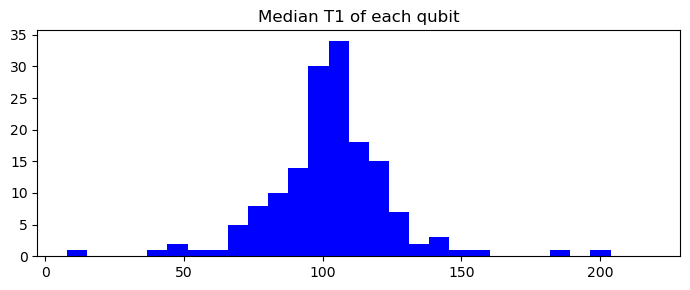

In [6]:
baseline = daily[qubits].median()

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(baseline.min() * 0.9, baseline.max() * 1.1, 30)
ax.hist(baseline, bins=bins, color="blue", linewidth=1)
ax.set(title="Median T1 of each qubit")
plt.tight_layout()
plt.show()

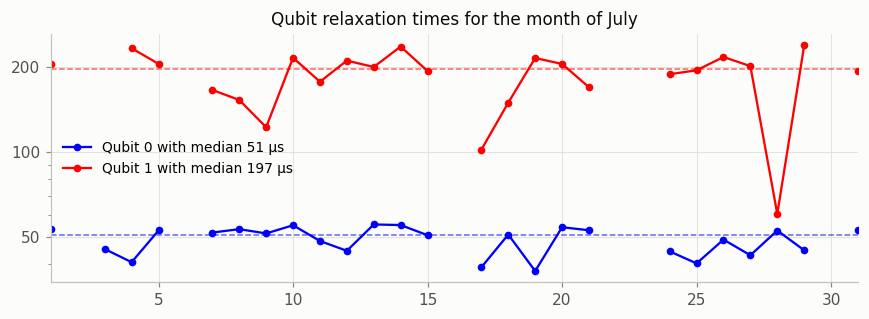

In [27]:
# All of July
july = daily[[0, 1]].loc["2026-07-01":"2026-07-31"]
july.index = july.index.day

fig, ax = plt.subplots(figsize=(8, 3))
for qubit, color in [(0, "blue"), (1, "red")]:
    median = july[qubit].median()
    ax.plot(july.index, july[qubit], marker="o", ms=4, color=color,
            label=f"Qubit {qubit} with median {median:.0f} µs")
    ax.axhline(median, color=color, ls="--", lw=1, alpha=0.6)
log_axis(ax, "y")
ax.set(xlim=(1, 31), title="Qubit relaxation times for the month of July")
ax.legend()
plt.tight_layout()
plt.show()

Note that from this plot, it's clear to see that both qubits have different median T1 times and have wildly different fluctuations. For example, both qubits have around the same T1 time at the 28th, even though qubit 1 has a much higher median.

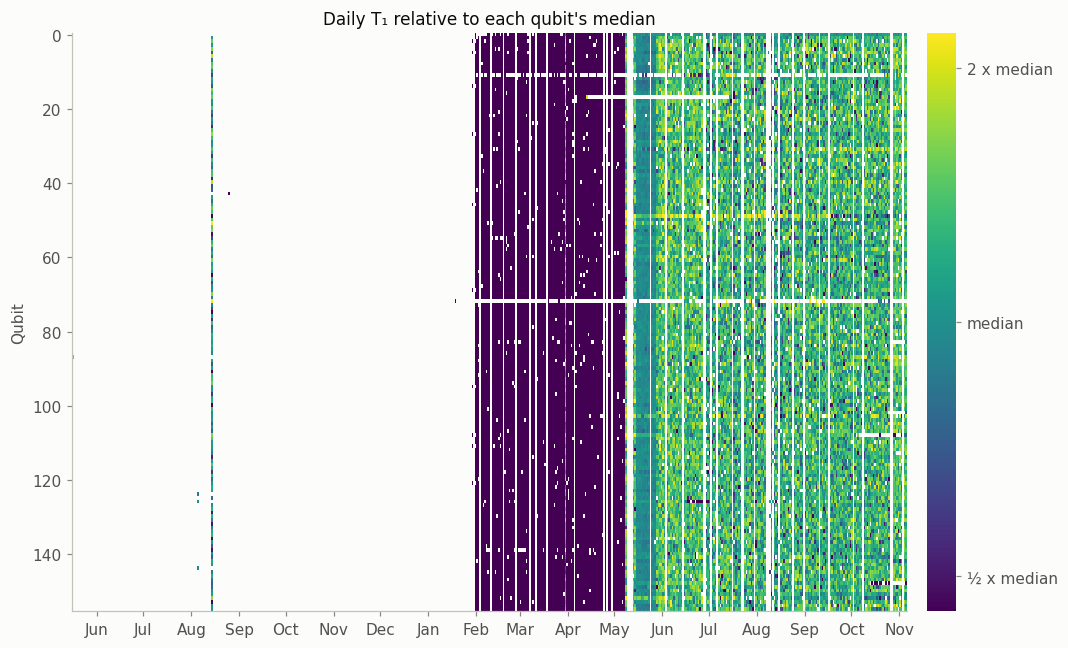

In [24]:
limit = np.log(2.2)
x0 = mdates.date2num(dates[0].tz_localize(None))
x1 = x0 + len(dates)

fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(resid.T.to_numpy(), aspect="auto", vmin=-limit, vmax=limit,
                  interpolation="nearest", extent=[x0, x1, len(qubits) - 0.5, -0.5])
ax.grid(False)
ax.xaxis_date()
month_axis(ax)
rows = [i for i, q in enumerate(qubits) if q % 20 == 0]
ax.set_yticks(rows, [str(qubits[i]) for i in rows])
ax.set(ylabel="Qubit", title="Daily T₁ relative to each qubit's median")
bar = fig.colorbar(image, ax=ax, pad=0.02, ticks=np.log([0.5, 1, 2]))
bar.ax.set_yticklabels(["½ x median", "median", "2 x median"])
bar.outline.set_visible(False)
plt.tight_layout()
plt.show()